<a href="https://colab.research.google.com/github/JantikarShobith/BIS_LAB/blob/main/1BM24CS351_Week5_GWO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Optimizing 6-Generator Power Grid Dispatch via Grey Wolf Optimizer...

Iter   1 | Total Cost: $ 16234.55/hr | Loss:  6.13 MW | Mismatch: 3.9517 MW
Iter  50 | Total Cost: $ 15624.67/hr | Loss:  5.53 MW | Mismatch: 0.3103 MW
Iter 100 | Total Cost: $ 15624.67/hr | Loss:  5.53 MW | Mismatch: 0.3103 MW
Iter 150 | Total Cost: $ 15624.67/hr | Loss:  5.53 MW | Mismatch: 0.3103 MW
Iter 200 | Total Cost: $ 15696.30/hr | Loss:  5.47 MW | Mismatch: 0.0768 MW
Iter 250 | Total Cost: $ 15687.28/hr | Loss:  5.44 MW | Mismatch: 0.1023 MW
Iter 300 | Total Cost: $ 15654.52/hr | Loss:  5.57 MW | Mismatch: 0.0446 MW

         OPTIMAL SMART GRID ECONOMIC DISPATCH SCHEDULE            
 Generator 1 Output :  459.10 MW  (Bounds: [100.0, 500.0] | Load:  89.8%)
 Generator 2 Output :  197.70 MW  (Bounds: [ 50.0, 200.0] | Load:  98.5%)
 Generator 3 Output :  288.41 MW  (Bounds: [ 80.0, 300.0] | Load:  94.7%)
 Generator 4 Output :   50.08 MW  (Bounds: [ 50.0, 150.0] | Load:   0.1%)
 Generator 5 Output :  199.48 MW 

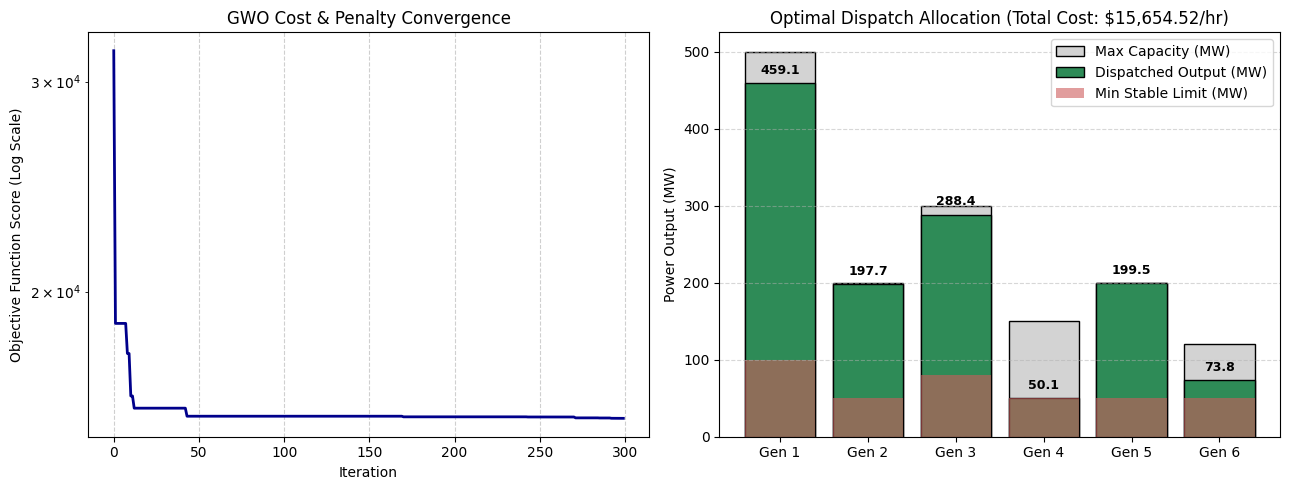

In [1]:
import numpy as np
import matplotlib.pyplot as plt

TOTAL_DEMAND = 1263.0

GENERATORS = np.array([
    [100.0, 500.0, 240.0, 7.0, 0.0070, 300.0, 0.035],  # Gen 1: Large Baseload Coal
    [ 50.0, 200.0, 200.0, 10.0, 0.0095, 200.0, 0.042], # Gen 2: Mid-merit Gas
    [ 80.0, 300.0, 220.0, 8.5, 0.0090, 200.0, 0.042],  # Gen 3: Combined Cycle
    [ 50.0, 150.0, 200.0, 11.0, 0.0090, 150.0, 0.063], # Gen 4: Peaker Unit A
    [ 50.0, 200.0, 220.0, 10.5, 0.0080, 150.0, 0.063], # Gen 5: Peaker Unit B
    [ 50.0, 120.0, 190.0, 12.0, 0.0075, 100.0, 0.084], # Gen 6: Fast-Response Turbine
])

NUM_GENS = len(GENERATORS)
P_MIN = GENERATORS[:, 0]
P_MAX = GENERATORS[:, 1]


B_LOSS = np.array([0.000017, 0.000012, 0.000007, 0.000024, 0.000019, 0.000021])


NUM_WOLVES = 50
MAX_ITER = 300
PENALTY_FACTOR = 1000.0  # Strict penalty for power supply/demand mismatch


def evaluate_dispatch(power_outputs):
    """
    Calculates hourly fuel cost ($/hr) + valve-point loading ripples
    + penalty for any mismatch between generated power and city demand.
    """
    a = GENERATORS[:, 2]
    b = GENERATORS[:, 3]
    c = GENERATORS[:, 4]
    e = GENERATORS[:, 5]
    f = GENERATORS[:, 6]

    # 1. Quadratic Fuel Cost + Non-Convex Valve-Point Ripple
    quadratic_cost = a + b * power_outputs + c * (power_outputs ** 2)
    valve_ripple = np.abs(e * np.sin(f * (P_MIN - power_outputs)))
    total_fuel_cost = np.sum(quadratic_cost + valve_ripple)

    # 2. Transmission Loss Calculation: P_loss = sum(B_i * P_i^2)
    transmission_loss = np.sum(B_LOSS * (power_outputs ** 2))

    # 3. Power Balance Constraint Violation
    power_mismatch = abs(np.sum(power_outputs) - (TOTAL_DEMAND + transmission_loss))
    penalty = PENALTY_FACTOR * (power_mismatch ** 2)

    return total_fuel_cost + penalty, total_fuel_cost, transmission_loss, power_mismatch


# =========================================================
# 4. GREY WOLF OPTIMIZER FOR ECONOMIC LOAD DISPATCH
# =========================================================
def run_gwo_dispatch():
    np.random.seed(42)

    # Initialize Pack Positions within each generator's [P_min, P_max] bounds
    positions = np.random.uniform(P_MIN, P_MAX, size=(NUM_WOLVES, NUM_GENS))

    # Initialize Alpha, Beta, Delta leaders
    alpha_pos = np.zeros(NUM_GENS)
    alpha_score = float("inf")

    beta_pos = np.zeros(NUM_GENS)
    beta_score = float("inf")

    delta_pos = np.zeros(NUM_GENS)
    delta_score = float("inf")

    # Initial Pack Evaluation
    for i in range(NUM_WOLVES):
        fitness, _, _, _ = evaluate_dispatch(positions[i])
        if fitness < alpha_score:
            alpha_score, alpha_pos = fitness, positions[i].copy()
        elif fitness < beta_score:
            beta_score, beta_pos = fitness, positions[i].copy()
        elif fitness < delta_score:
            delta_score, delta_pos = fitness, positions[i].copy()

    convergence_curve = []

    print("Optimizing 6-Generator Power Grid Dispatch via Grey Wolf Optimizer...\n")

    # Main Hunting Loop
    for it in range(MAX_ITER):
        # Linearly decrease parameter 'a' from 2.0 to 0.0
        a = 2.0 - it * (2.0 / MAX_ITER)

        for i in range(NUM_WOLVES):
            # Vectorized updates across all 6 generators simultaneously
            r1, r2 = np.random.rand(NUM_GENS), np.random.rand(NUM_GENS)
            A1 = 2 * a * r1 - a
            C1 = 2 * r2
            D_alpha = np.abs(C1 * alpha_pos - positions[i])
            X1 = alpha_pos - A1 * D_alpha

            r1, r2 = np.random.rand(NUM_GENS), np.random.rand(NUM_GENS)
            A2 = 2 * a * r1 - a
            C2 = 2 * r2
            D_beta = np.abs(C2 * beta_pos - positions[i])
            X2 = beta_pos - A2 * D_beta

            r1, r2 = np.random.rand(NUM_GENS), np.random.rand(NUM_GENS)
            A3 = 2 * a * r1 - a
            C3 = 2 * r2
            D_delta = np.abs(C3 * delta_pos - positions[i])
            X3 = delta_pos - A3 * D_delta

            # Update wolf dispatch schedule and enforce generator MW limits
            positions[i] = np.clip((X1 + X2 + X3) / 3.0, P_MIN, P_MAX)

        # Re-evaluate pack and update leadership hierarchy
        for i in range(NUM_WOLVES):
            fitness, _, _, _ = evaluate_dispatch(positions[i])

            if fitness < alpha_score:
                delta_score, delta_pos = beta_score, beta_pos.copy()
                beta_score, beta_pos = alpha_score, alpha_pos.copy()
                alpha_score, alpha_pos = fitness, positions[i].copy()
            elif fitness < beta_score:
                delta_score, delta_pos = beta_score, beta_pos.copy()
                beta_score, beta_pos = fitness, positions[i].copy()
            elif fitness < delta_score:
                delta_score, delta_pos = fitness, positions[i].copy()

        convergence_curve.append(alpha_score)

        if (it + 1) % 50 == 0 or it == 0:
            _, fuel_cost, loss, mismatch = evaluate_dispatch(alpha_pos)
            print(f"Iter {it+1:3d} | Total Cost: ${fuel_cost:9.2f}/hr | Loss: {loss:5.2f} MW | Mismatch: {mismatch:.4f} MW")

    return alpha_pos, convergence_curve


# =========================================================
# 5. EXECUTION & VISUALIZATION
# =========================================================
best_dispatch, history = run_gwo_dispatch()
_, final_fuel_cost, final_loss, final_mismatch = evaluate_dispatch(best_dispatch)

print("\n==================================================================")
print("         OPTIMAL SMART GRID ECONOMIC DISPATCH SCHEDULE            ")
print("==================================================================")
for idx in range(NUM_GENS):
    utilization = ((best_dispatch[idx] - P_MIN[idx]) / (P_MAX[idx] - P_MIN[idx])) * 100
    print(f" Generator {idx+1} Output : {best_dispatch[idx]:7.2f} MW  "
          f"(Bounds: [{P_MIN[idx]:5.1f}, {P_MAX[idx]:5.1f}] | Load: {utilization:5.1f}%)")
print("------------------------------------------------------------------")
print(f" Total Power Generated : {np.sum(best_dispatch):8.2f} MW")
print(f" City Load Demand      : {TOTAL_DEMAND:8.2f} MW")
print(f" Transmission Loss     : {final_loss:8.2f} MW")
print(f" Power Balance Error   : {final_mismatch:8.4f} MW")
print(f" Minimum Fuel Cost     : ${final_fuel_cost:8.2f} / hour")
print("==================================================================")

# Visualization: Convergence & Generator Allocation Bar Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left Plot: Convergence Curve
ax1.plot(history, color='darkblue', linewidth=2)
ax1.set_title("GWO Cost & Penalty Convergence")
ax1.set_xlabel("Iteration")
ax1.set_ylabel("Objective Function Score (Log Scale)")
ax1.set_yscale("log")
ax1.grid(True, linestyle='--', alpha=0.6)

# Right Plot: Optimal Generator Power Allocation vs Capacity Limits
gen_labels = [f"Gen {i+1}" for i in range(NUM_GENS)]
x_pos = np.arange(NUM_GENS)

ax2.bar(x_pos, P_MAX, color='lightgray', edgecolor='black', label='Max Capacity (MW)')
ax2.bar(x_pos, best_dispatch, color='seagreen', edgecolor='black', label='Dispatched Output (MW)')
ax2.bar(x_pos, P_MIN, color='indianred', alpha=0.6, label='Min Stable Limit (MW)')

for i, val in enumerate(best_dispatch):
    ax2.text(i, val + 12, f"{val:.1f}", ha='center', fontsize=9, fontweight='bold')

ax2.set_xticks(x_pos)
ax2.set_xticklabels(gen_labels)
ax2.set_ylabel("Power Output (MW)")
ax2.set_title(f"Optimal Dispatch Allocation (Total Cost: ${final_fuel_cost:,.2f}/hr)")
ax2.legend(loc='upper right')
ax2.grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()